In [22]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score
import matplotlib.pyplot as plt


In [23]:
df = pd.read_csv('D:/Decision Modelling/Class resources/audit.csv')
df


,diabetes,hypertension,sector,wealth,gender,age,education,smoking,alcohol,glucose,systolic_pressure,diastolic_pressure,BMI
0,0,0,1,3,2,25,3,0,0,110,121.0,75.0,21.770000
1,0,0,1,3,2,22,3,0,0,99,116.0,78.0,19.889999
2,0,1,1,4,2,32,3,0,0,120,121.0,78.0,22.100000
3,0,0,1,2,2,33,2,0,0,140,138.0,87.0,21.860001
4,0,0,1,2,2,18,2,0,0,100,110.0,72.0,18.920000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
692888,0,0,2,1,2,45,0,0,0,109,114.5,77.5,22.240000
692889,0,0,2,2,1,37,0,1,1,125,129.0,81.0,24.020000
692890,0,0,2,2,2,34,0,0,0,115,105.0,71.0,20.030001
692891,0,0,2,2,1,18,2,1,0,82,128.0,79.0,20.730000


In [24]:
X = df.drop('diabetes', axis= 1)
y = df['diabetes']

In [25]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size = 0.20,
    random_state = 1,
    stratify = y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size = 0.25,
    random_state = 1,
    stratify = y_dev
)

In [26]:

dt_model = DecisionTreeClassifier(
    criterion='gini',
    class_weight='balanced', 
    random_state=1
)


dt_model.fit(X_dev, y_dev)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,1
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,'balanced'


In [27]:
y_pred = dt_model.predict(X_test)

In [28]:
results = pd.DataFrame({
    "Actual (Test)": y_test.values,
    "Predicted": y_pred
})

results["Prediction"] = np.where(
    results["Actual (Test)"] == results["Predicted"],
    "Correct",
    "Incorrect"
)
results


,Actual (Test),Predicted,Prediction
0,0,0,Correct
1,0,0,Correct
2,0,0,Correct
3,0,1,Incorrect
4,0,0,Correct
...,...,...,...
138574,0,0,Correct
138575,0,0,Correct
138576,0,0,Correct
138577,0,0,Correct


In [29]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.9693532209064866


In [30]:
print("--- Classification Report: Unpruned ---")
print(classification_report(y_test, y_pred, target_names=['No Diabetes (0)', 'Diabetes (1)']))

--- Classification Report: Unpruned ---
                 precision    recall  f1-score   support

No Diabetes (0)       0.98      0.99      0.98    135941
   Diabetes (1)       0.17      0.16      0.17      2638

       accuracy                           0.97    138579
      macro avg       0.58      0.57      0.58    138579
   weighted avg       0.97      0.97      0.97    138579



In [31]:
print("Confusion Matrix")
print(confusion_matrix(y_test, y_pred))

Confusion Matrix
[[133906   2035]
 [  2212    426]]


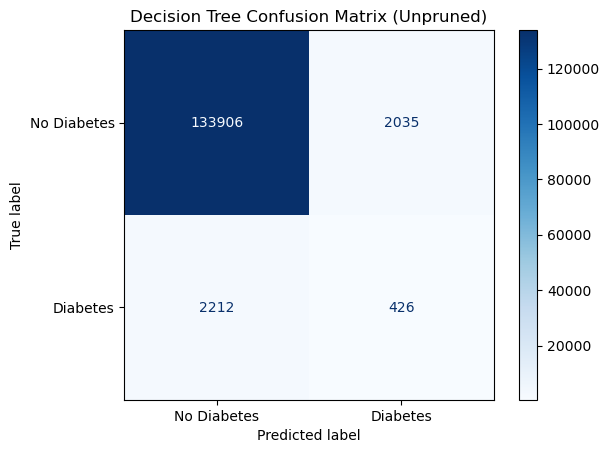

In [32]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Diabetes', 'Diabetes'])
disp.plot(cmap='Blues', values_format='d')
plt.title("Decision Tree Confusion Matrix (Unpruned)")
plt.show()

In [33]:
temp_model = DecisionTreeClassifier(
    criterion="gini",
    class_weight='balanced',
    random_state= 1
)

temp_model.fit(X_train, y_train)

path = temp_model.cost_complexity_pruning_path(
    X_train, y_train
)

ccp_alphas = path.ccp_alphas

print("Possible ccp_alpha values:")
print(ccp_alphas)

Possible ccp_alpha values:
[0.00000000e+00 2.45009630e-21 2.45009630e-21 ... 1.63681643e-02
 6.17180509e-02 8.89517470e-02]


In [34]:
models = []
train_f1 = []
validation_f1 = []


sample_alphas = np.unique(ccp_alphas[::500])
print("Alpha values to test:", len(sample_alphas))

for alpha in sample_alphas:
    model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=10,
        ccp_alpha=float(alpha),
        class_weight='balanced',
        random_state=1
    )
    model.fit(X_train, y_train)
    models.append(model)
    train_f1.append(f1_score(y_train, model.predict(X_train), zero_division=0))
    validation_f1.append(f1_score(y_val, model.predict(X_val), zero_division=0))

Alpha values to test: 21


In [35]:
best_index = np.argmax(validation_f1)
best_alpha = sample_alphas[best_index]
print("Best ccp_alpha:", best_alpha)
print("Best validation F1-score:", validation_f1[best_index])

Best ccp_alpha: 3.2353794997352576e-05
Best validation F1-score: 0.14637505062778453


In [36]:
final_model = DecisionTreeClassifier(
    criterion="gini",
    ccp_alpha=best_alpha,
    class_weight='balanced',
    max_depth=10,
    random_state=1
)

final_model.fit(X_dev, y_dev)

y_pred_pruned = final_model.predict(X_test)

In [37]:
results = pd.DataFrame({
    "Actual (Test)": y_test.values,
    "Predicted": y_pred_pruned
})

results["Prediction_Pruned"] = np.where(
    results["Actual (Test)"] == results["Predicted"],
    "Correct",
    "Incorrect"
)
results

,Actual (Test),Predicted,Prediction_Pruned
0,0,1,Incorrect
1,0,1,Incorrect
2,0,0,Correct
3,0,1,Incorrect
4,0,0,Correct
...,...,...,...
138574,0,0,Correct
138575,0,0,Correct
138576,0,1,Incorrect
138577,0,0,Correct


In [38]:
print("Classifaction Report (Pruned):")
print(classification_report(
    y_test,
    y_pred_pruned
))

Classifaction Report (Pruned):
              precision    recall  f1-score   support

           0       0.99      0.86      0.92    135941
           1       0.08      0.67      0.15      2638

    accuracy                           0.85    138579
   macro avg       0.54      0.76      0.53    138579
weighted avg       0.98      0.85      0.90    138579



In [39]:
print("Confusion Matrix (Pruned):")
print(confusion_matrix(y_test, y_pred_pruned))

Confusion Matrix (Pruned):
[[116251  19690]
 [   883   1755]]


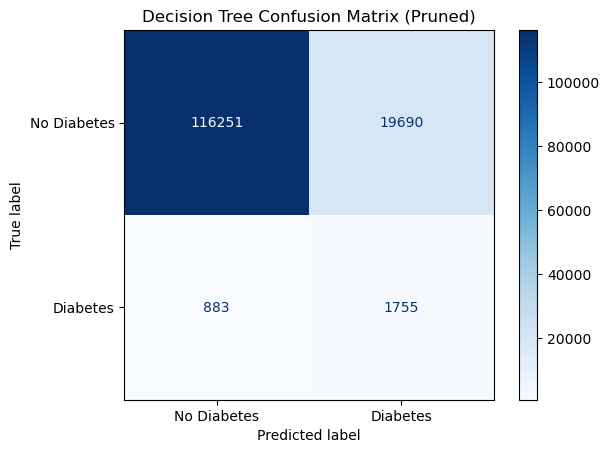

In [40]:
cm = confusion_matrix(y_test, y_pred_pruned)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Diabetes', 'Diabetes'])
disp.plot(cmap='Blues', values_format='d')  # 'd' formats numbers as clean integers instead of scientific notation
plt.title("Decision Tree Confusion Matrix (Pruned)")
plt.show()

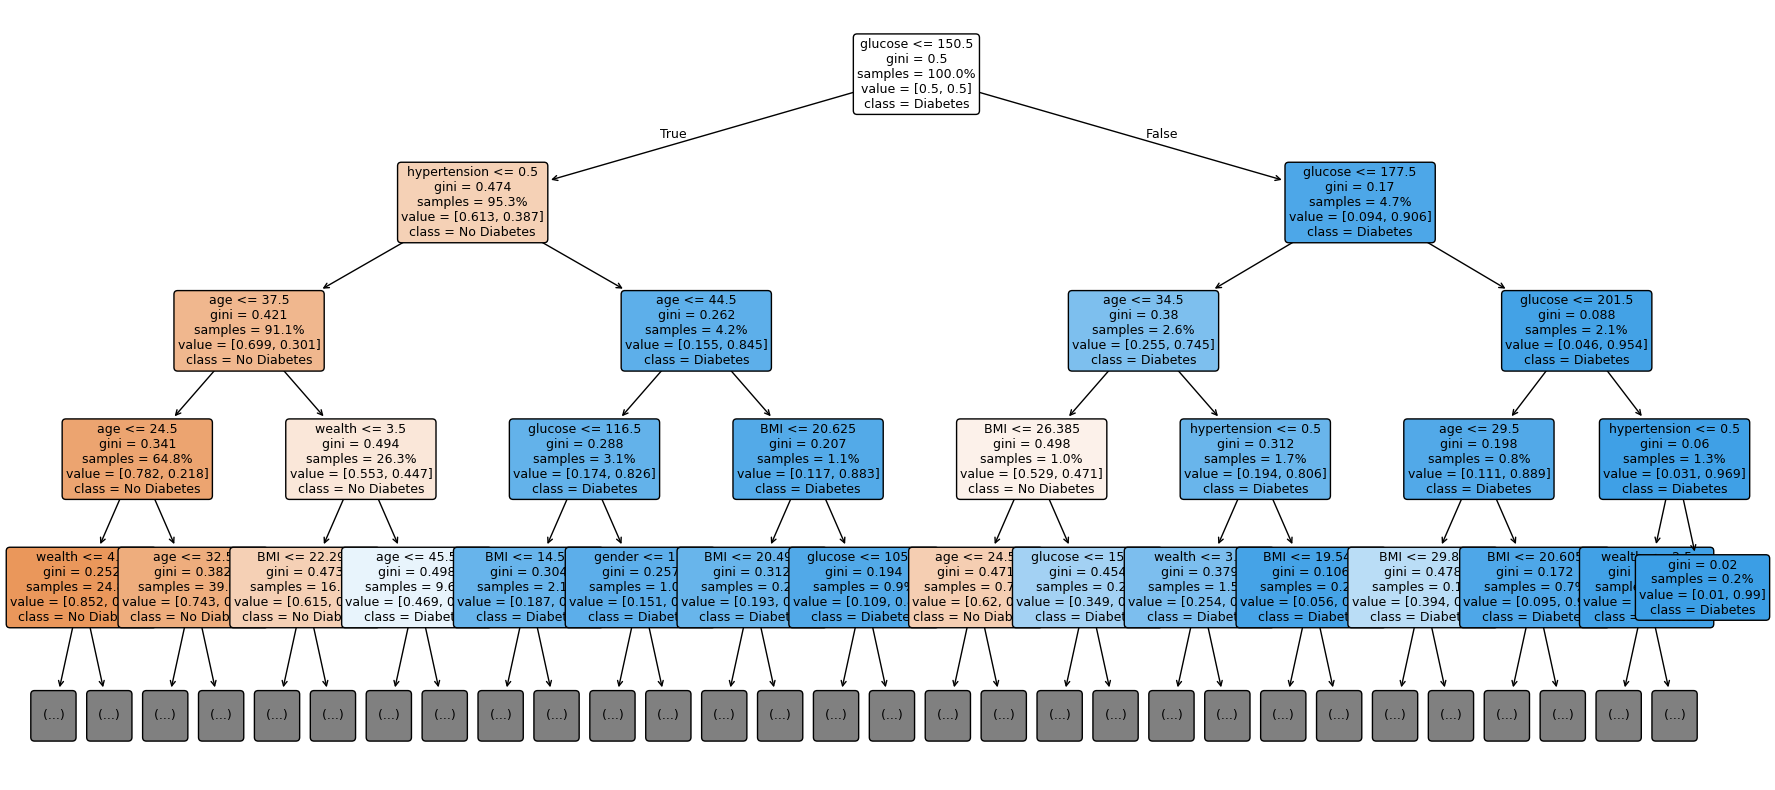

In [41]:
plt.figure(figsize=(22, 10))

plot_tree(
    final_model,
    feature_names=X.columns,
    class_names=["No Diabetes", "Diabetes"],
    filled=True,
    rounded=True,
    max_depth=4,
    proportion=True,
    fontsize=9
)

plt.show()

In [42]:
importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': final_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

importance_df['Importance (%)'] = (importance_df['Importance'] * 100).round(2)

print(importance_df)

               Feature  Importance  Importance (%)
8              glucose    0.482650           48.26
0         hypertension    0.300155           30.02
4                  age    0.119659           11.97
11                 BMI    0.033829            3.38
2               wealth    0.019588            1.96
9    systolic_pressure    0.017461            1.75
10  diastolic_pressure    0.014328            1.43
5            education    0.005697            0.57
1               sector    0.002202            0.22
3               gender    0.002185            0.22
7              alcohol    0.001954            0.20
6              smoking    0.000292            0.03
